---
title: "L3-04 · Tensor products and joint systems"
short_title: "Tensor products and joint systems"
subtitle: "Joint systems multiply: a 2-outcome system and a 3-outcome system have 2 x 3 = 6 joint outcomes, a product vector fills that grid with products of entries, and a joint vector whose grid does not have rank 1 cannot be split into two separate parts."
description: "Build joint vectors with the tensor product in a fixed basis order, count the dimension of a joint system, and decide with the rank test whether a joint vector or a joint probability table factors into independent parts."
tags: [level-3, coursebook]
---

(lesson-l3-04)=

:::{div}
:class: qcai-meta
![Level 3 icon](../../_static/icons/qicon-level-3.svg) **Level 3 · High-school bridge** · about 100 minutes  
**Big idea.** Joint systems multiply: a 2-outcome system and a 3-outcome system have 2 x 3 = 6 joint outcomes, a product vector fills that grid with products of entries, and a joint vector whose grid does not have rank 1 cannot be split into two separate parts.  
**Before this lesson.** [L3-02](#lesson-l3-02), [L3-03](#lesson-l3-03)  
**Lab.** [Entanglement and Bell tests](../../labs/06-entanglement-bell.ipynb)
:::

## What you will be able to do

- Compute $a\otimes b$ for vectors of any sizes in the order $00, 01, \dots$ and state the dimension of $\mathbb{C}^m\otimes\mathbb{C}^n$ and of $n$ qubits.
- Use the rules $\langle a\otimes b, c\otimes d\rangle = \langle a, c\rangle\langle b, d\rangle$ and $(A\otimes B)(a\otimes b) = Aa\otimes Bb$ in calculations, and prove them from entries.
- Decide whether a joint vector is a product by the rank of its table (for two qubits: $c_{00}c_{11} - c_{01}c_{10} = 0$), and factor it when it is.
- Distinguish a correlated classical probability table from an entangled amplitude vector, and say what the table alone does not show.

## Why this matters

Suppose a model has one variable with 2 outcomes and another with 3. Describing them separately takes $2 + 3 = 5$ numbers. Describing them together takes $2\times 3 = 6$, one for each pair of outcomes, and the gap widens fast: ten two-outcome variables need 20 numbers separately but $2^{10} = 1024$ jointly. The extra room is where correlations live. Whether you are writing a joint probability table for a causal model or a state vector for two qubits, the joint space is built the same way, by the tensor product.

That raises the central question of this lesson: given a joint vector, can it be split into a part for each subsystem? For probabilities, splitting means independence. For quantum amplitudes, failure to split is entanglement, the resource behind teleportation and Bell tests. One algebraic test, the rank of a table, answers both. But the same test applied to different kinds of entries means different things, and keeping those meanings apart is as important as the computation.

:::{dropdown} Key terms

**Tensor (Kronecker) product**
: For $a \in \mathbb{C}^m$, $b \in \mathbb{C}^n$, the vector $a\otimes b \in \mathbb{C}^{mn}$ whose entry at position $(j, k)$ is $a_j b_k$, listed in the order $00, 01, \dots$

**Joint basis**
: The $mn$ vectors $e_j\otimes f_k$, written $|jk\rangle$; they form an orthonormal basis of $\mathbb{C}^m\otimes\mathbb{C}^n$.

**Product vector**
: A joint vector that equals $a\otimes b$ for some $a$ and $b$.

**Entangled state**
: A normalized joint state vector that is not a product vector for the stated split into subsystems A and B.

**Rank**
: The number of independent columns of a matrix; a nonzero table is a product exactly when its rank is 1.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l3_04 as _lessonfigs

## Joint outcomes multiply

Let system A have outcomes $0, 1$ and system B outcomes $0, 1, 2$. A joint outcome is a pair $jk$, and the pairs form a $2\times 3$ grid. To write a joint vector we must list the grid in a line, and every convention in this course reads it **row by row**: $00, 01, 02, 10, 11, 12$. Position $jk$ sits at index $3j + k$ (counting from 0); for two qubits the order is $00, 01, 10, 11$.

:::{figure} ../../_static/animations/l3_04_product_grid.mp4
:alt: A 2 by 3 grid of joint outcomes 00 to 12 is built from a 2-outcome system and a 3-outcome system, unrolled row by row into a column of six entries, followed by a bar chart of 2 to the n reaching 1024 at n equal to 10.
:width: 100%

Two outcomes times three outcomes: $2 \times 3 = 6$ joint outcomes, read row by row. With $n$ two-outcome systems the count is $2^n$.
:::

:::{dropdown} What the animation shows
System A's outcomes 0 and 1 label the two rows of a grid and system B's outcomes 0, 1, 2 label its three columns. The six cells fill with the joint labels 00, 01, 02, 10, 11, 12, and the screen states $2 \times 3 = 6$ joint outcomes, not $2 + 3 = 5$. The cells then move one by one, row by row, into a single column of six entries, with the rule that pair $ab$ sits at position $3a + b$. Finally a bar chart shows the number of joint outcomes $2^n$ for $n = 1$ to $10$ two-outcome systems, ending at $2^{10} = 1024$.
:::

:::{prf:definition} Tensor product of vectors
:label: def-l3-04-kron
For $a = (a_0, \dots, a_{m-1}) \in \mathbb{C}^m$ and $b = (b_0, \dots, b_{n-1}) \in \mathbb{C}^n$, the **tensor product** $a\otimes b \in \mathbb{C}^{mn}$ has entry $a_j b_k$ at position $nj + k$. In blocks, $a\otimes b = (a_0 b,\ a_1 b,\ \dots,\ a_{m-1} b)$. The space $\mathbb{C}^m\otimes\mathbb{C}^n$ is $\mathbb{C}^{mn}$ with this labeling of positions by pairs $(j, k)$.
:::

$$
(a_0, a_1)\otimes(b_0, b_1) = (a_0 b_0,\ a_0 b_1,\ a_1 b_0,\ a_1 b_1) \quad \text{in the order } 00, 01, 10, 11
$$ (eq-l3-04-kron)

:::{prf:proposition} The joint basis and the dimension count
:label: prop-l3-04-basis
If $e_0, \dots, e_{m-1}$ and $f_0, \dots, f_{n-1}$ are the standard bases, the $mn$ vectors $e_j\otimes f_k$ are exactly the standard basis vectors of $\mathbb{C}^{mn}$ (the one with a single 1 at position $nj + k$). Hence $\dim(\mathbb{C}^m\otimes\mathbb{C}^n) = mn$, and $n$ qubits live in $(\mathbb{C}^2)^{\otimes n} = \mathbb{C}^{2^n}$.
:::

The proof is one line: $e_j\otimes f_k$ has entry $1\cdot 1$ at position $(j, k)$ and $0$ everywhere else. The physicist's notation is $|jk\rangle = |j\rangle\otimes|k\rangle$. Exponential growth is real and practical: a state of 30 qubits has $2^{30} \approx 1.07\times 10^{9}$ complex amplitudes, 16 GiB at 16 bytes each, and every added qubit doubles it. In general a joint vector is **not** a product; only the products are cheap to store, with $m + n$ numbers instead of $mn$.

## Filling the grid: the Kronecker product

Take $a = (3/5, 4/5)$ and $b = (2/3, 2/3, 1/3)$, both unit vectors. Put $a$ down the side of the $2\times 3$ grid and $b$ across the top; each cell gets the product of its row label and column label. Reading the grid row by row gives $a\otimes b = (\tfrac25, \tfrac25, \tfrac15, \tfrac{8}{15}, \tfrac{8}{15}, \tfrac{4}{15})$. The grid itself is the outer product $a\,b^{\mathsf T}$, and its second row is $\tfrac43$ times its first: every row of a product grid is a multiple of $b$.

:::{figure} ../../_static/animations/l3_04_kronecker_fill.mp4
:alt: The entries of a = (3/5, 4/5) label the rows and those of b = (2/3, 2/3, 1/3) label the columns; each cell fills with the product of its labels, and the grid unrolls into the six-entry vector a tensor b with its two blocks 3/5 b and 4/5 b.
:width: 100%

Each cell is (row entry) times (column entry). Read row by row, the grid is $a\otimes b$, made of the blocks $\tfrac35 b$ and $\tfrac45 b$.
:::

:::{dropdown} What the animation shows
The vectors $a = (\tfrac35, \tfrac45)$ and $b = (\tfrac23, \tfrac23, \tfrac13)$ appear at the top. Their entries label the rows and columns of an empty $2\times 3$ grid. One cell at a time, the row label and column label are highlighted and their product drops into the cell: $\tfrac25, \tfrac25, \tfrac15$ in the first row and $\tfrac{8}{15}, \tfrac{8}{15}, \tfrac{4}{15}$ in the second. A caption notes that the grid is $a\,b^{\mathsf T}$ and that row 2 is $\tfrac43$ times row 1. The six numbers then move, row by row, into the column vector $a\otimes b$, and two boxes mark its blocks $\tfrac35 b$ and $\tfrac45 b$. The last line checks the length: $\|a\otimes b\|^2 = \tfrac{9}{25} + \tfrac{144}{225} = 1$.
:::

:::{prf:proposition} Rules of the tensor product
:label: prop-l3-04-rules
For vectors and matrices of matching sizes: (i) $\otimes$ is linear in each factor, e.g. $(a + a')\otimes b = a\otimes b + a'\otimes b$ and $(sa)\otimes b = s(a\otimes b) = a\otimes(sb)$; (ii) $\langle a\otimes b, c\otimes d\rangle = \langle a, c\rangle\,\langle b, d\rangle$, so $\|a\otimes b\| = \|a\|\,\|b\|$; (iii) with $(A\otimes B)_{(j,k),(l,m)} = A_{jl}B_{km}$, $\;(A\otimes B)(a\otimes b) = (Aa)\otimes(Bb)$.
:::

:::{prf:proof}
(i) is immediate from the entries $a_j b_k$. (ii): $\langle a\otimes b, c\otimes d\rangle = \sum_{j,k}\overline{a_j b_k}\,c_j d_k = \left(\sum_j \bar a_j c_j\right)\left(\sum_k \bar b_k d_k\right)$. (iii): entry $(j, k)$ of the left side is $\sum_{l,m} A_{jl}B_{km}\,a_l b_m = \left(\sum_l A_{jl}a_l\right)\left(\sum_m B_{km}b_m\right) = (Aa)_j\,(Bb)_k$, which is entry $(j, k)$ of $(Aa)\otimes(Bb)$.
:::


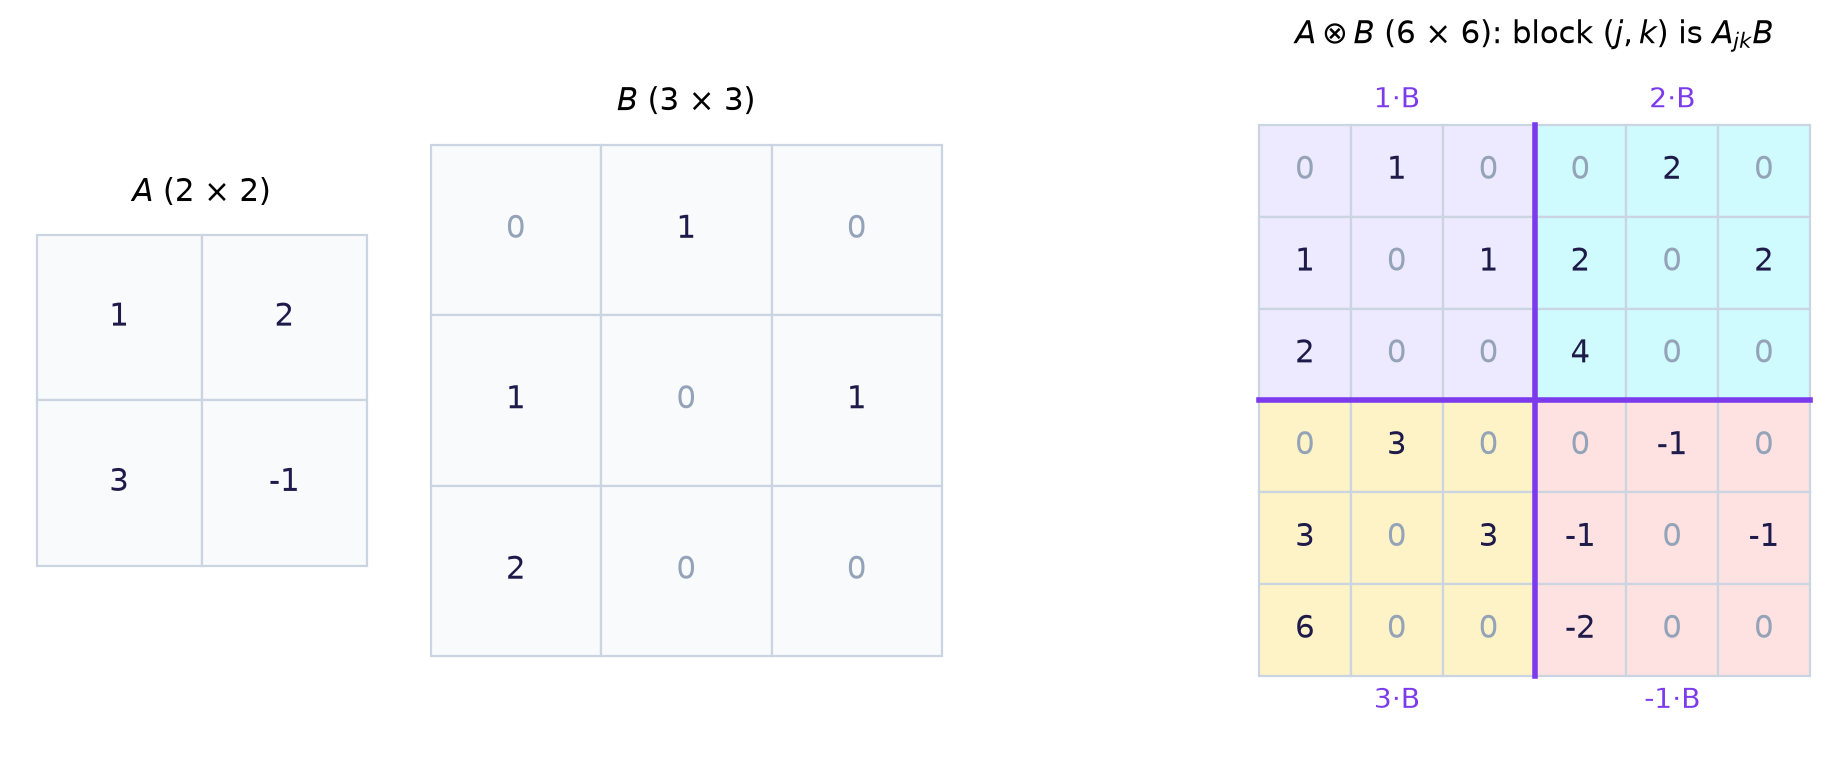

In [2]:
_show_mpl(_lessonfigs.kron_blocks())

*The Kronecker product of matrices has the same block pattern as for vectors: the $6\times 6$ matrix $A\otimes B$ is a $2\times 2$ array of blocks, and block $(j, k)$ is $A_{jk}B$. Rule (iii) says this matrix acts on product vectors one factor at a time.*

:::{prf:remark} The order of the factors matters
$a\otimes b$ and $b\otimes a$ contain the same numbers in different positions: $(1, 0)\otimes(0, 1) = (0, 1, 0, 0) = |01\rangle$ but $(0, 1)\otimes(1, 0) = (0, 0, 1, 0) = |10\rangle$. The first factor always labels the rows of the grid (the left digit). NumPy's `np.kron` follows the same convention.
:::

## Product or not: the rank test

:::{prf:definition} Product states and entangled states
:label: def-l3-04-entangled
A unit vector $\psi \in \mathbb{C}^m\otimes\mathbb{C}^n$ is a **product state** (for the split into A and B) if $\psi = a\otimes b$ for some $a \in \mathbb{C}^m$, $b \in \mathbb{C}^n$. Otherwise $\psi$ is **entangled**. The definition refers to a stated split; with three or more subsystems one must say which groups are being separated.
:::

:::{prf:theorem} Rank criterion
:label: thm-l3-04-rank
Arrange $c \in \mathbb{C}^m\otimes\mathbb{C}^n$ as the $m\times n$ table $C$ with $C_{jk} = c_{jk}$. Then $c$ is a product vector if and only if $\operatorname{rank} C \le 1$.
:::

:::{prf:proof}
If $c = a\otimes b$ then $C_{jk} = a_j b_k$, so $C = a\,b^{\mathsf T}$ and every column $b_k a$ is a multiple of $a$: the rank is at most 1. Conversely, if $C = 0$ then $c = 0\otimes 0$. If $\operatorname{rank} C = 1$, all columns are multiples of one nonzero column vector $a$; write column $k$ as $b_k a$. Then $C_{jk} = a_j b_k$, that is $c = a\otimes b$ with $b = (b_0, \dots, b_{n-1})$.
:::

:::{prf:corollary} Two qubits
:label: cor-l3-04-det
A two-qubit vector $c = (c_{00}, c_{01}, c_{10}, c_{11})$ is a product if and only if $c_{00}c_{11} - c_{01}c_{10} = 0$, because a $2\times 2$ table has rank at most 1 exactly when its determinant is 0.
:::

$$
c = a\otimes b \iff \det\begin{pmatrix} c_{00} & c_{01} \\ c_{10} & c_{11}\end{pmatrix} = c_{00}c_{11} - c_{01}c_{10} = 0
$$ (eq-l3-04-det)

:::{figure} ../../_static/animations/l3_04_rank_test.mp4
:alt: Two 2 by 2 amplitude tables: a product table with determinant 0 and the table of (1, 0, 0, 1)/sqrt 2 with determinant one half; then the family cos theta |00> + sin theta |11> with its determinant traced from 0 up to one half and back to 0.
:width: 100%

The test of [](#eq-l3-04-det) on a product, on $(|00\rangle + |11\rangle)/\sqrt2$, and on the family $\cos\theta\,|00\rangle + \sin\theta\,|11\rangle$, whose determinant is $\cos\theta\,\sin\theta$.
:::

:::{dropdown} What the animation shows
The rule $c = a\otimes b$ exactly when the determinant of the $2\times 2$ table is zero appears at the top. On the left, the product of $(0.6, 0.8)$ and $(0.8, 0.6)$ is written as the table with rows $0.48, 0.36$ and $0.64, 0.48$; the screen computes $0.48 \cdot 0.48 - 0.36 \cdot 0.64 = 0$ and notes that the rows are proportional. On the right, the vector $(1, 0, 0, 1)/\sqrt2$ gives the table with $1/\sqrt2$ on the diagonal and 0 elsewhere; its determinant is $\tfrac12 \ne 0$. The reason is shown in words: if $a_0 b_0 \ne 0$ and $a_1 b_1 \ne 0$ then $a_0 b_1 \ne 0$, but the table has a zero there, so this vector cannot factor and is entangled. Then the family $c(\theta) = \cos\theta\,|00\rangle + \sin\theta\,|11\rangle$ is shown as a table whose diagonal entries change as $\theta$ runs from 0 to $\pi/2$, while a graph traces the determinant $\cos\theta\,\sin\theta$: zero at both ends, where the state is a product, and largest, $\tfrac12$, at $\theta = \pi/4$.
:::


In [3]:
_show(_lessonfigs.entangle_explorer())

**Explore.** Move $\theta$ to change $c(\theta) = \cos\theta\,|00\rangle + \sin\theta\,|11\rangle$. The table shows the four amplitudes; the graph shows its determinant, which is zero only at the product states $\theta = 0^\circ$ and $90^\circ$.

:::{dropdown} What the figure shows
The first panel is a $2\times 2$ heat map of the amplitudes $c_{ab}$ with rows $a = 0, 1$ and columns $b = 0, 1$; only the diagonal entries $\cos\theta$ and $\sin\theta$ are nonzero. The second panel plots $\det = \cos\theta\,\sin\theta$ for $\theta$ from $0^\circ$ to $90^\circ$, with diamonds at the two product states and a red marker at the chosen $\theta$. At $45^\circ$ the table is $0.707$ on the diagonal and the determinant reaches its maximum $0.5$.
:::

The determinant is more than a yes/no test. For a normalized two-qubit state, $2|c_{00}c_{11} - c_{01}c_{10}|$ is a standard measure of entanglement (the concurrence of a pure state); it is 0 for products and 1 for $(|00\rangle + |11\rangle)/\sqrt2$. [L5-04](#lesson-l5-04) returns to it.

## Classical tables obey the same algebra

A joint probability table $P(a, b)$ for two random variables is also an $m\times n$ grid. The variables are **independent** exactly when $P(a, b) = p(a)\,q(b)$ for all $a, b$ [@openstax_independent]; that is, $P = p\,q^{\mathsf T}$, a rank-one table. So the rank test detects dependence too. The table $\begin{pmatrix} 0.3 & 0.2 \\ 0.3 & 0.2\end{pmatrix}$ has determinant $0.06 - 0.06 = 0$ and equals the product of its marginals $(0.5, 0.5)$ and $(0.6, 0.4)$. The table $\begin{pmatrix} 0.5 & 0 \\ 0 & 0.5\end{pmatrix}$ has determinant $\tfrac14$: the two variables always agree.

```{mermaid}
graph TD
  Z[Common cause Z: one coin flip] --> A[Envelope A]
  Z --> B[Envelope B]
  A -.- B
```

*A common cause produces a correlated table with no quantum physics involved: one coin flip decides what goes into both envelopes, so the contents always match and $P = \begin{pmatrix} 1/2 & 0 \\ 0 & 1/2\end{pmatrix}$ has rank 2. The dotted link marks the correlation, not a causal arrow.*

:::{warning} A correlated table is not entanglement
Measuring $(|00\rangle + |11\rangle)/\sqrt2$ in the standard basis gives the same table $\begin{pmatrix} 1/2 & 0 \\ 0 & 1/2\end{pmatrix}$ as the two envelopes. The table alone cannot tell them apart. Entanglement is a property of amplitudes, and showing that no classical common cause can reproduce the data requires measurements in other bases and a Bell inequality, the subject of Level 5 [@nielsenchuang; @preskill]. Always state what the entries of a joint vector mean before drawing a conclusion from its rank.
:::

`np.kron` is the tensor product with the row-by-row order of this lesson, and `np.reshape(c, (m, n))` turns a joint vector back into its table. The cell checks the grid example, the rank test on four vectors, the rules of the tensor product, two classical tables and the memory cost of qubits.


In [4]:
import numpy as np
from fractions import Fraction

# a 2-entry and a 3-entry vector give a 6-entry joint vector, ordered 00, 01, 02, 10, 11, 12
a = np.array([3/5, 4/5])
b = np.array([2/3, 2/3, 1/3])
ab = np.kron(a, b)
print('a (x) b =', [str(Fraction(x).limit_denominator(100)) for x in ab])
print('same as the outer product a b^T read row by row:', np.allclose(ab, np.outer(a, b).reshape(-1)))
print('norms multiply:', round(np.linalg.norm(ab), 12), '=', round(np.linalg.norm(a) * np.linalg.norm(b), 12))

# order matters: (1,0) (x) (0,1) is |01>, but (0,1) (x) (1,0) is |10>
print(np.kron([1, 0], [0, 1]), np.kron([0, 1], [1, 0]))

def is_product(c, m, n, tol=1e-10):
    """A joint vector on m x n outcomes factors exactly when its m x n table has rank at most 1."""
    return np.linalg.matrix_rank(np.reshape(c, (m, n)), tol=tol) <= 1

prod = np.kron([0.6, 0.8], [0.8, 0.6])
bell = np.array([1, 0, 0, 1]) / np.sqrt(2)
for name, c in (('(0.48, 0.36, 0.64, 0.48)', prod), ('(1, 0, 0, 1)/sqrt2', bell),
                ('(1, 1, i, i)/2', np.array([1, 1, 1j, 1j]) / 2), ('(1, 1, 1, -1)/2', np.array([1, 1, 1, -1]) / 2)):
    C = np.reshape(c, (2, 2))
    print(f'{name:26s} det = {complex(np.linalg.det(C)):.3f}  product: {is_product(c, 2, 2)}')
print('the 2 x 3 vector a (x) b is a product:', is_product(ab, 2, 3))

# matrices: (A (x) B)(x (x) y) = (A x) (x) (B y), and inner products multiply
H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
I2 = np.eye(2)
e0 = np.array([1, 0])
print('(H (x) I)|00> =', (np.kron(H, I2) @ np.kron(e0, e0)).round(4), ' = (H|0>) (x) |0>:',
      np.allclose(np.kron(H, I2) @ np.kron(e0, e0), np.kron(H @ e0, e0)))
rng = np.random.default_rng(11)
x, y, u, v = (rng.normal(size=2) + 1j * rng.normal(size=2) for _ in range(4))
print('<x(x)y, u(x)v> = <x,u><y,v>:', np.isclose(np.vdot(np.kron(x, y), np.kron(u, v)), np.vdot(x, u) * np.vdot(y, v)))

# classical joint tables: independent exactly when the table has rank 1
indep = np.array([[0.3, 0.2], [0.3, 0.2]])
corr = np.array([[0.5, 0.0], [0.0, 0.5]])
for name, P in (('independent', indep), ('common cause', corr)):
    pa, pb = P.sum(axis=1), P.sum(axis=0)
    print(f'{name:13s} det = {np.linalg.det(P):.3f}  equals product of marginals: {np.allclose(P, np.outer(pa, pb))}')

# size: n qubits need 2^n complex amplitudes (16 bytes each in complex128)
for n in (10, 30):
    print(n, 'qubits:', 2**n, 'amplitudes,', 16 * 2**n / 2**30, 'GiB')

a (x) b = ['2/5', '2/5', '1/5', '8/15', '8/15', '4/15']
same as the outer product a b^T read row by row: True
norms multiply: 1.0 = 1.0
[0 1 0 0] [0 0 1 0]
(0.48, 0.36, 0.64, 0.48)   det = -0.000+0.000j  product: True
(1, 0, 0, 1)/sqrt2         det = 0.500+0.000j  product: False
(1, 1, i, i)/2             det = 0.000+0.000j  product: True
(1, 1, 1, -1)/2            det = -0.500+0.000j  product: False
the 2 x 3 vector a (x) b is a product: True
(H (x) I)|00> = [0.7071 0.     0.7071 0.    ]  = (H|0>) (x) |0>: True
<x(x)y, u(x)v> = <x,u><y,v>: True
independent   det = 0.000  equals product of marginals: True
common cause  det = 0.250  equals product of marginals: False
10 qubits: 1024 amplitudes, 1.52587890625e-05 GiB
30 qubits: 1073741824 amplitudes, 16.0 GiB


## Worked example

:::{admonition} Factor it or prove it cannot be factored
:class: tip

Decide whether each two-qubit state is a product, and factor it if it is: (a) $c = \frac12(1, 1, i, i)$; (b) $d = \frac12(1, 1, 1, -1)$.

1. (a) Table: $C = \frac12\begin{pmatrix} 1 & 1 \\ i & i\end{pmatrix}$. Determinant: $\frac14(1\cdot i - 1\cdot i) = 0$, so $c$ is a product.
2. (a) Factor: the second row is $i$ times the first, so take $b \propto (1, 1)$ and $a \propto (1, i)$. Normalizing, $c = \frac{1}{\sqrt2}(1, i)\otimes\frac{1}{\sqrt2}(1, 1)$. Check: $\frac12(1\cdot 1,\ 1\cdot 1,\ i\cdot 1,\ i\cdot 1) = \frac12(1, 1, i, i)$.
3. (b) Table: $D = \frac12\begin{pmatrix} 1 & 1 \\ 1 & -1\end{pmatrix}$. Determinant: $\frac14(-1 - 1) = -\frac12 \ne 0$, so $d$ has rank 2 and is entangled.
4. (b) Direct check: if $d = a\otimes b$ then $a_0b_0 = a_0b_1 = a_1b_0 = \frac12$, so $a_0, a_1, b_0, b_1 \ne 0$, $b_0 = b_1$ and $a_0 = a_1$; but then $a_1 b_1 = a_0 b_0 = \frac12$, not $-\frac12$. Contradiction.

**Result.** $c = \frac{1}{\sqrt2}(1, i)\otimes\frac{1}{\sqrt2}(1, 1)$ is a product state; $d$ is entangled, with $2|\det D| = 1$, as entangled as two qubits can be.
:::

## Exercises

**1. (Core)** Compute $(0, 1)\otimes(1, 0)$. Which joint basis outcome has probability 1?

:::{dropdown} Solution
$(0\cdot 1,\ 0\cdot 0,\ 1\cdot 1,\ 1\cdot 0) = (0, 0, 1, 0)$. The 1 is at position $10$: system A gives 1 and system B gives 0, with probability $|1|^2 = 1$.
:::

**2. (Core)** What is the dimension of (i) three qubits, (ii) $\mathbb{C}^2\otimes\mathbb{C}^3\otimes\mathbb{C}^2$? In the second case, at which index (from 0) does the basis vector $|1\,2\,0\rangle$ sit?

:::{dropdown} Solution
(i) $2^3 = 8$. (ii) $2\cdot 3\cdot 2 = 12$. Reading digits as a mixed-radix number with place values $3\cdot 2 = 6$, $2$ and $1$, the index of $|1\,2\,0\rangle$ is $1\cdot 6 + 2\cdot 2 + 0 = 10$.
:::

**3. (Stretch)** Is $\frac{1}{\sqrt2}(0, 1, 1, 0)$ a product state?

:::{dropdown} Solution
The table is $\frac{1}{\sqrt2}\begin{pmatrix} 0 & 1 \\ 1 & 0\end{pmatrix}$ with determinant $\frac12(0 - 1) = -\frac12 \ne 0$. It is entangled: a product would need $a_0 b_1 \ne 0$ and $a_1 b_0 \ne 0$, forcing $a_0 b_0 \ne 0$, but that entry is 0.
:::

**4. (Stretch)** Which of these joint probability tables describe independent variables? $P_1 = \begin{pmatrix} 0.3 & 0.2 \\ 0.3 & 0.2\end{pmatrix}$, $P_2 = \begin{pmatrix} 0.4 & 0.1 \\ 0.1 & 0.4\end{pmatrix}$. Give the marginals.

:::{dropdown} Solution
$P_1$: row sums $(0.5, 0.5)$, column sums $(0.6, 0.4)$, and $0.5\cdot 0.6 = 0.3$, $0.5\cdot 0.4 = 0.2$ in every cell, so independent (determinant $0.06 - 0.06 = 0$). $P_2$: marginals $(0.5, 0.5)$ and $(0.5, 0.5)$, but $0.5\cdot 0.5 = 0.25 \ne 0.4$, so dependent (determinant $0.16 - 0.01 = 0.15 \ne 0$).
:::

**5. (Stretch)** Let $H = \frac{1}{\sqrt2}\begin{pmatrix} 1 & 1 \\ 1 & -1\end{pmatrix}$ and $I$ the $2\times 2$ identity. Compute $(H\otimes I)\,|00\rangle$ in two ways: with rule (iii), and by writing out the $4\times 4$ matrix $H\otimes I$.

:::{dropdown} Solution
Rule (iii): $(H\otimes I)(e_0\otimes e_0) = (He_0)\otimes e_0 = \frac{1}{\sqrt2}(1, 1)\otimes(1, 0) = \frac{1}{\sqrt2}(1, 0, 1, 0)$. Matrix: $H\otimes I = \frac{1}{\sqrt2}\begin{pmatrix} 1 & 0 & 1 & 0 \\ 0 & 1 & 0 & 1 \\ 1 & 0 & -1 & 0 \\ 0 & 1 & 0 & -1\end{pmatrix}$; its first column, the image of $|00\rangle = (1, 0, 0, 0)$, is $\frac{1}{\sqrt2}(1, 0, 1, 0)$. Both agree: the first qubit is put in equal superposition, the second is untouched.
:::

**6. (Challenge)** Prove that a two-qubit vector with $c_{00} \ne 0$ and $c_{00}c_{11} = c_{01}c_{10}$ equals $a\otimes b$ with $a = (1,\ c_{10}/c_{00})$ and $b = (c_{00},\ c_{01})$. Use it to factor $c = \frac{1}{\sqrt{10}}(1, 2, 1, 2)$ into two unit vectors.

:::{dropdown} Solution
Compute $a\otimes b = (c_{00},\ c_{01},\ \tfrac{c_{10}}{c_{00}}c_{00},\ \tfrac{c_{10}}{c_{00}}c_{01}) = (c_{00}, c_{01}, c_{10}, \tfrac{c_{10}c_{01}}{c_{00}})$, and the last entry equals $c_{11}$ because $c_{10}c_{01} = c_{00}c_{11}$. For $c = \frac{1}{\sqrt{10}}(1, 2, 1, 2)$: $c_{00}c_{11} = \frac{2}{10} = c_{01}c_{10}$, so $a = (1, 1)$ and $b = \frac{1}{\sqrt{10}}(1, 2)$; normalized, $c = \frac{1}{\sqrt2}(1, 1)\otimes\frac{1}{\sqrt5}(1, 2)$. Check: $\frac{1}{\sqrt{10}}(1, 2, 1, 2)$.
:::

**7. (Challenge)** Show that $\cos\theta\,|00\rangle + \sin\theta\,|11\rangle$ is a product state exactly when $\theta$ is a multiple of $\pi/2$, and that $(|00\rangle + |11\rangle)/\sqrt2$ is not a product of any two vectors even after changing the basis of each qubit by unitary matrices $U$ and $V$.

:::{dropdown} Solution
The determinant is $\cos\theta\sin\theta - 0 = \frac12\sin 2\theta$, which vanishes exactly when $2\theta$ is a multiple of $\pi$. For the second part, suppose $(U\otimes V)\psi = a\otimes b$ with $\psi = (|00\rangle + |11\rangle)/\sqrt2$. Apply $U^\dagger\otimes V^\dagger$, the inverse of $U\otimes V$ by rule (iii): $\psi = (U^\dagger a)\otimes(V^\dagger b)$, a product, contradicting $\det = \frac12 \ne 0$. Being a product does not depend on the local bases.
:::

## Check your understanding

**1. How many amplitudes describe a general pure state of three qubits?**

- **A.** 6
- **B.** 9
- **C.** 3
- **D.** 8

:::{dropdown} Show the answer
**D. 8**

Dimensions multiply: $2\times 2\times 2 = 2^3 = 8$. Adding the sizes would give 6, which is the count for three separate qubits.
:::

**2. What is $(1, 2)\otimes(3, 4)$ in the order $00, 01, 10, 11$?**

- **A.** $(3, 4, 6, 8)$
- **B.** $(3, 6, 4, 8)$
- **C.** $(4, 6)$
- **D.** $(3, 8)$

:::{dropdown} Show the answer
**A. $(3, 4, 6, 8)$**

Entry $jk$ is $a_j b_k$: $1\cdot 3$, $1\cdot 4$, $2\cdot 3$, $2\cdot 4$. The vector $(3, 6, 4, 8)$ is $(3, 4)\otimes(1, 2)$, with the factors swapped.
:::

**3. Which two-qubit vector is a product of two one-qubit vectors?**

- **A.** $\frac12(1, 1, 1, -1)$
- **B.** $\frac{1}{\sqrt2}(0, 1, 1, 0)$
- **C.** $\frac{1}{\sqrt2}(1, 0, 0, 1)$
- **D.** $\frac12(1, 1, 1, 1)$

:::{dropdown} Show the answer
**D. $\frac12(1, 1, 1, 1)$**

$\frac12(1, 1, 1, 1) = \frac{1}{\sqrt2}(1, 1)\otimes\frac{1}{\sqrt2}(1, 1)$, and its table has determinant $\frac14(1 - 1) = 0$. The other three tables have determinants $\frac12$, $-\frac12$ and $-\frac12$.
:::

**4. In the product $ABv$ of two matrices and a vector, which matrix acts on $v$ first?** *(Review of [L3-03](#lesson-l3-03))*

- **A.** Both at once, entry by entry
- **B.** $A$
- **C.** $B$
- **D.** It depends on the sizes

:::{dropdown} Show the answer
**C. $B$**

$(AB)v = A(Bv)$: $B$ acts first and $A$ acts on the result.
:::

## Common misconceptions

- **"Joining systems adds dimensions: two qubits have $2 + 2 = 4$ amplitudes."** Dimensions multiply; for two qubits $2\times 2 = 4$ only happens to equal $2 + 2$. A qubit and a 3-outcome system give $6$, not $5$, and three qubits give $8$, not $6$.
- **"If the outcomes of two systems are always correlated, the systems are entangled."** Two envelopes filled after one coin flip are perfectly correlated with no quantum physics at all. Entanglement is a property of a joint amplitude vector, and showing it from data needs measurements in several bases.
- **"Every joint vector is some $a\otimes b$; one just has to find $a$ and $b$."** Products form a small subset: for two qubits they satisfy the equation $c_{00}c_{11} = c_{01}c_{10}$. The vector $(1, 0, 0, 1)/\sqrt2$ violates it and has no factorization.
- **"$a\otimes b$ and $b\otimes a$ are the same vector."** They hold the same numbers in different positions: $(1, 0)\otimes(0, 1) = |01\rangle$ but $(0, 1)\otimes(1, 0) = |10\rangle$. The first factor is the left digit.

:::{caution} Scope and limits
Basis order is a convention: this lesson and NumPy's `np.kron` read the grid row by row, so the first factor is the left digit (big-endian). Some quantum software orders qubits the other way, which permutes the entries; always check. The rank test decides whether a single vector factors; for mixed states (density matrices, Level 5) separability is much harder to decide. Exponential state size does not by itself imply a quantum computational advantage, and a correlated measurement table does not by itself demonstrate entanglement.
:::

:::{seealso} Where this leads
Eigenvectors in [L3-05](#lesson-l3-05) turn matrices into measurements: the eigenvectors of a Hermitian matrix form the basis in which a measurement reads a state. In Level 4 joint probability tables and their factorizations express independence and conditional independence in causal graphs. In Level 5 the two-qubit state $(|00\rangle + |11\rangle)/\sqrt2$ becomes the Bell state, gates such as $H\otimes I$ and CNOT act on joint vectors, and the singular value decomposition of the table (the Schmidt decomposition) refines the rank test into a full description of entanglement.
:::

:::{dropdown} For instructors

**Why this lesson.** The tensor product is the point where quantum information stops looking like ordinary vector algebra. Students who see it as a grid of products can count dimensions, compute Kronecker products, and recognize non-product vectors by eye, and they meet the distinction between classical correlation and entanglement before Bell inequalities [@nielsenchuang; @preskill; @watrous].

**Teaching notes.**

- Start with the $2\times 3$ grid on paper, not with qubits; the unequal sizes stop students from confusing $2\times 2$ with $2 + 2$.
- Have students compute one Kronecker product by hand in grid form and then confirm with `np.kron`, including a swapped order.
- Before the rank theorem, ask: which $2\times 2$ tables can be written as (column) times (row)? Students usually discover that the rows must be proportional.
- Use the envelope example to separate correlation from entanglement, and promise the Bell-test resolution in Level 5 rather than claiming it here.

**Assessment.** The first stretch exercise and the third check question test the rank criterion; the classical-table exercise tests whether students can carry it to independence; the $H\otimes I$ exercise tests the mixed-product rule. The second challenge (invariance under local unitaries) shows whether students can combine this lesson with [L3-03](#lesson-l3-03).

**Going further.** Compute the singular values of the table of $\cos\theta\,|00\rangle + \sin\theta\,|11\rangle$ (they are $|\cos\theta|$ and $|\sin\theta|$) and explain why the number of nonzero singular values, the Schmidt rank, is unchanged by local unitaries. Nielsen and Chuang, section 2.5, presents the Schmidt decomposition [@nielsenchuang].

:::

## References

This lesson draws on [@nielsenchuang; @preskill; @watrous; @openstax_independent; @mml].

**Further reading.**

- [@nielsenchuang]: Section 2.1.7 defines tensor products; section 2.5 develops the Schmidt decomposition.
- [@watrous]: Chapter 1 treats tensor products of complex Euclidean spaces with exact conventions.

**Next:** [L3-05 · Eigenvectors and observables](#lesson-l3-05)
